In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

file_rotterdamXLS =  r"\Users\svenv\OneDrive\Documenten\2DMM30_stochastics_simulation\Simulation_assignment\rotterdam_dataset_02.xlsx"
df_rotterdam = pd.read_excel(file_rotterdamXLS)
df_rotterdam.head()

,Arrival_Date,Vessel_ID,Vessel_Type,Cargo_tons,Berth_Time_hr
0,2022-01-01 10:33:00,V000001,Container,10597,25.5
1,2022-01-01 19:24:00,V000002,Container,12878,19.2
2,2022-01-01 17:29:00,V000003,Container,11917,24.2
3,2022-01-01 06:23:00,V000004,Container,8757,16.7
4,2022-01-01 05:14:00,V000005,Container,27508,21.8


In [69]:
df_times = df_rotterdam[['Arrival_Date', 'Vessel_Type']].copy()
df_times = df_times.sort_values(by='Arrival_Date').reset_index(drop=True)
df_times.head()

,Arrival_Date,Vessel_Type
0,2022-01-01 00:04:00,Bulk
1,2022-01-01 00:55:00,Tanker
2,2022-01-01 01:13:00,Tanker
3,2022-01-01 02:08:00,Tanker
4,2022-01-01 02:59:00,Container


In [70]:
df_times_diff = df_times.copy()
df_times_diff['Time_diff'] = df_times_diff['Arrival_Date'].diff()
df_times_diff.head()

,Arrival_Date,Vessel_Type,Time_diff
0,2022-01-01 00:04:00,Bulk,NaT
1,2022-01-01 00:55:00,Tanker,0 days 00:51:00
2,2022-01-01 01:13:00,Tanker,0 days 00:18:00
3,2022-01-01 02:08:00,Tanker,0 days 00:55:00
4,2022-01-01 02:59:00,Container,0 days 00:51:00


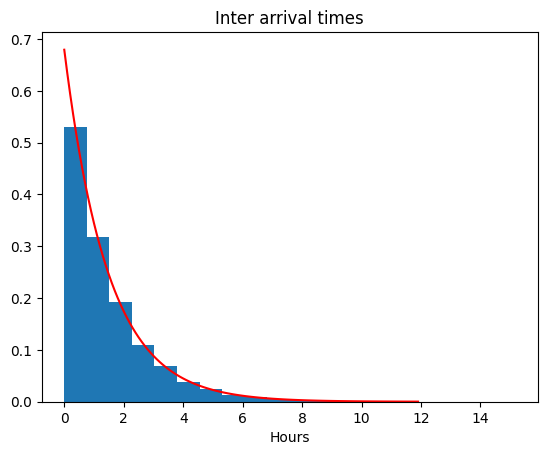

0.1767775414458439


In [71]:
exponDist = stats.expon(scale = df_times_diff['Time_diff'].dt.total_seconds().mean() / 3600)

plt.figure()
plt.hist(df_times_diff['Time_diff'].dropna().dt.total_seconds() / 3600, density=True, bins=20)
xs = np.arange(0, 12, 0.1)
ys = exponDist.pdf(xs)
plt.plot(xs, ys, 'r')
plt.title('Inter arrival times')
plt.xlabel('Hours')
plt.show()

tst = stats.kstest(df_times_diff['Time_diff'].dropna().dt.total_seconds() / 3600, exponDist.cdf)
print(tst.pvalue)

In [72]:
df_times_bulk = df_times[df_times['Vessel_Type'] == 'Bulk'].copy()
df_times_bulk['Time_diff'] = df_times_bulk['Arrival_Date'].diff()

df_times_tanker = df_times[df_times['Vessel_Type'] == 'Tanker'].copy()
df_times_tanker['Time_diff'] = df_times_tanker['Arrival_Date'].diff()

df_times_container = df_times[df_times['Vessel_Type'] == 'Container'].copy()
df_times_container['Time_diff'] = df_times_container['Arrival_Date'].diff()

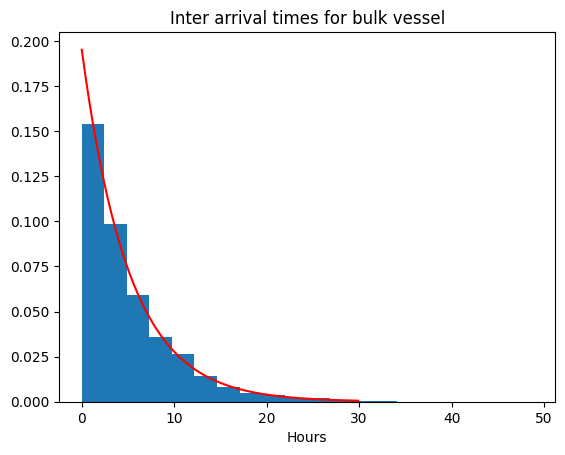

lambda = 0.19516622594965433
0.43810273134307454


In [73]:
exponDist_bulk = stats.expon(scale = df_times_bulk['Time_diff'].dt.total_seconds().mean() / 3600)

plt.figure()
plt.hist(df_times_bulk['Time_diff'].dropna().dt.total_seconds() / 3600, density=True, bins=20)
xs = np.arange(0, 30, 0.1)
ys = exponDist_bulk.pdf(xs)
plt.plot(xs, ys, 'r')
plt.title('Inter arrival times for bulk vessel')
plt.xlabel('Hours')
plt.show()

print(f'lambda = {1 / (df_times_bulk['Time_diff'].dt.total_seconds().mean() / 3600)}')
tst_bulk = stats.kstest(df_times_bulk['Time_diff'].dropna().dt.total_seconds() / 3600, exponDist_bulk.cdf)
print(tst_bulk.pvalue)

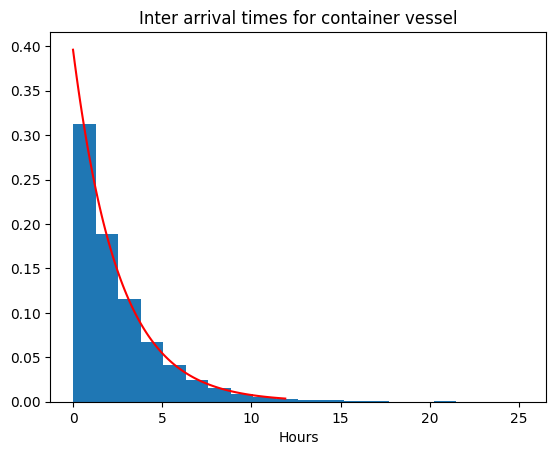

lambda = 0.39617224880382773
0.3630906118936189


In [74]:
exponDist_container = stats.expon(scale = df_times_container['Time_diff'].dt.total_seconds().mean() / 3600)

plt.figure()
plt.hist(df_times_container['Time_diff'].dropna().dt.total_seconds() / 3600, density=True, bins=20)
xs = np.arange(0, 12, 0.1)
ys = exponDist_container.pdf(xs)
plt.plot(xs, ys, 'r')
plt.title('Inter arrival times for container vessel')
plt.xlabel('Hours')
plt.show()

print(f'lambda = {1 / (df_times_container['Time_diff'].dt.total_seconds().mean() / 3600)}')
tst_container = stats.kstest(df_times_container['Time_diff'].dropna().dt.total_seconds() / 3600, exponDist_container.cdf)
print(tst_container.pvalue)

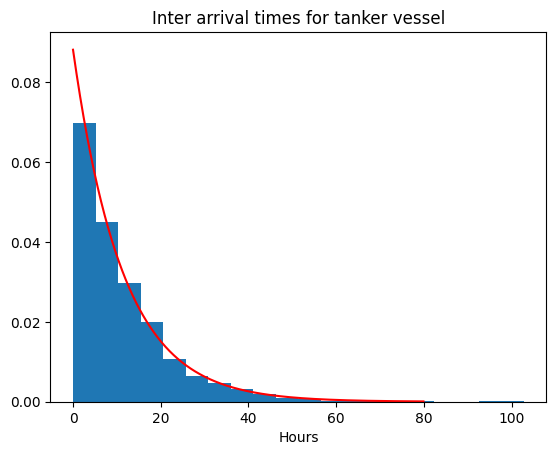

lambda = 0.08807691137546017
0.6671983227526651


In [75]:
exponDist_tanker = stats.expon(scale = df_times_tanker['Time_diff'].dt.total_seconds().mean() / 3600)

plt.figure()
plt.hist(df_times_tanker['Time_diff'].dropna().dt.total_seconds() / 3600, density=True, bins=20)
xs = np.arange(0, 80, 0.1)
ys = exponDist_tanker.pdf(xs)
plt.plot(xs, ys, 'r')
plt.title('Inter arrival times for tanker vessel')
plt.xlabel('Hours')
plt.show()

print(f'lambda = {1 / (df_times_tanker['Time_diff'].dt.total_seconds().mean() / 3600)}')
tst_tanker = stats.kstest(df_times_tanker['Time_diff'].dropna().dt.total_seconds() / 3600, exponDist_tanker.cdf)
print(tst_tanker.pvalue)